In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
import warnings


In [5]:
df = pd.read_csv("Customer-Churn-Records.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


# EDA

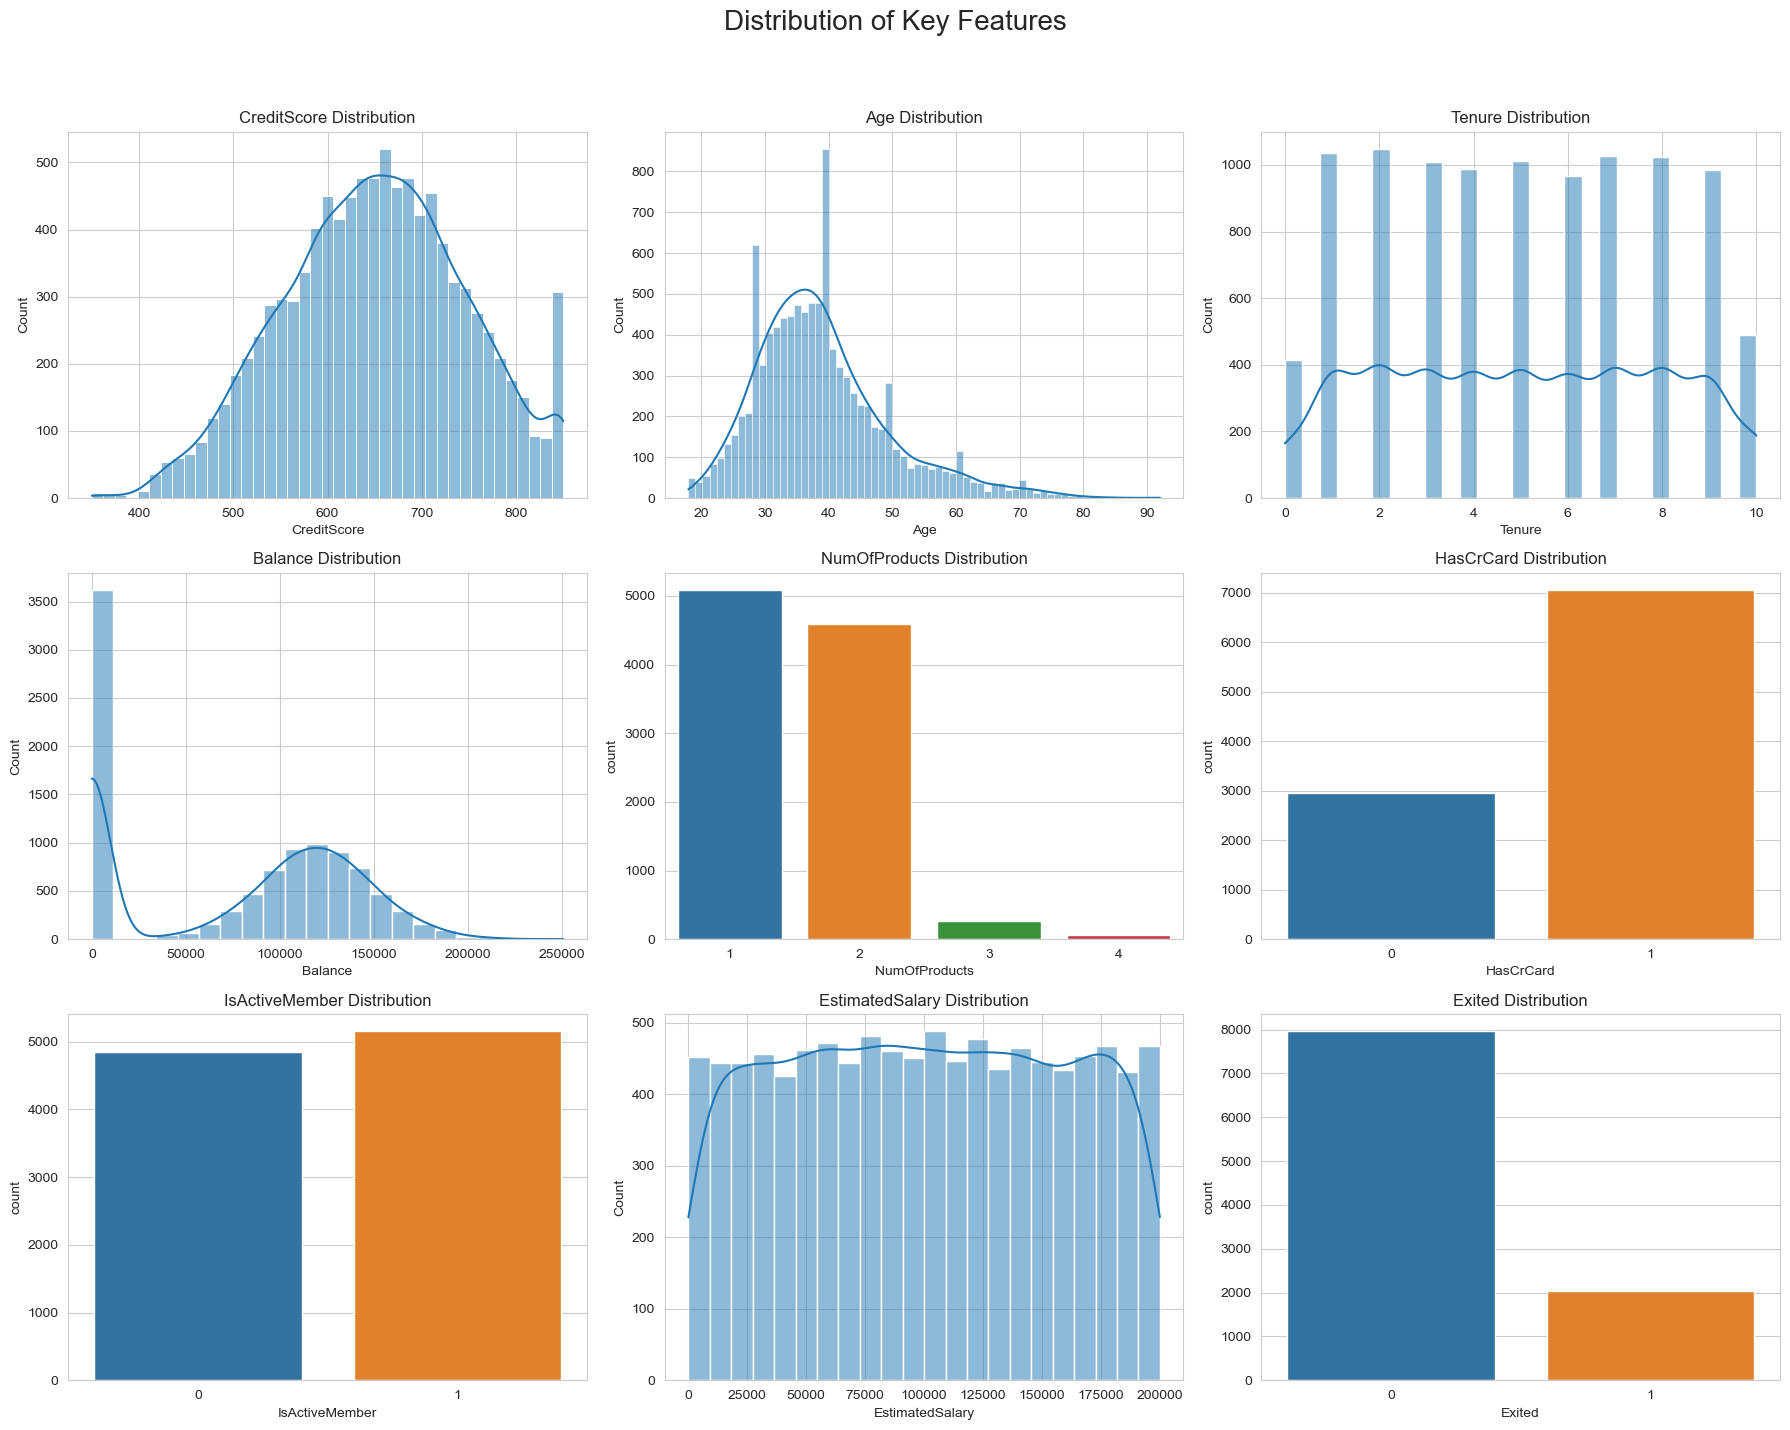

In [6]:
# Set the aesthetic style of the plots
sns.set_style('whitegrid')

# Create a figure and a set of subplots
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle('Distribution of Key Features', fontsize=20)

# Plot distribution of CreditScore
sns.histplot(df['CreditScore'], kde=True, ax=axes[0, 0])
axes[0, 0].set_title('CreditScore Distribution')

# Plot distribution of Age
sns.histplot(df['Age'], kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Age Distribution')

# Plot distribution of Tenure
sns.histplot(df['Tenure'], kde=True, ax=axes[0, 2])
axes[0, 2].set_title('Tenure Distribution')

# Plot distribution of Balance
sns.histplot(df['Balance'], kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Balance Distribution')

# Plot distribution of NumOfProducts
sns.countplot(x='NumOfProducts', data=df, ax=axes[1, 1])
axes[1, 1].set_title('NumOfProducts Distribution')

# Plot distribution of HasCrCard
sns.countplot(x='HasCrCard', data=df, ax=axes[1, 2])
axes[1, 2].set_title('HasCrCard Distribution')

# Plot distribution of IsActiveMember
sns.countplot(x='IsActiveMember', data=df, ax=axes[2, 0])
axes[2, 0].set_title('IsActiveMember Distribution')

# Plot distribution of EstimatedSalary
sns.histplot(df['EstimatedSalary'], kde=True, ax=axes[2, 1])
axes[2, 1].set_title('EstimatedSalary Distribution')

# Plot distribution of Exited
sns.countplot(x='Exited', data=df, ax=axes[2, 2])
axes[2, 2].set_title('Exited Distribution')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [7]:
# Checking for missing values
missing_values = df.isnull().sum()
missing_values

RowNumber             0
CustomerId            0
Surname               0
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Complain              0
Satisfaction Score    0
Card Type             0
Point Earned          0
dtype: int64

In [8]:
# Summary statistics
summary_statistics = df.describe()
summary_statistics

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


In [9]:
# Checking the shape of the DataFrame
df.shape

(10000, 18)

In [10]:
# Check for duplicates
duplicates = df.duplicated().sum()
duplicates

0

In [11]:
# Check data types
df.dtypes

RowNumber               int64
CustomerId              int64
Surname                object
CreditScore             int64
Geography              object
Gender                 object
Age                     int64
Tenure                  int64
Balance               float64
NumOfProducts           int64
HasCrCard               int64
IsActiveMember          int64
EstimatedSalary       float64
Exited                  int64
Complain                int64
Satisfaction Score      int64
Card Type              object
Point Earned            int64
dtype: object

In [12]:
#outlier checking
# Remove non-numeric columns for outlier detection
numerical_columns = df.select_dtypes(include=['int64','float64']).columns
numerical_columns

Index(['RowNumber', 'CustomerId', 'CreditScore', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited', 'Complain', 'Satisfaction Score', 'Point Earned'],
      dtype='object')

In [13]:
# Calculate IQR for numerical columns
Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outlier
outliers = ((df[numerical_columns] < lower_bound) | (df[numerical_columns] > upper_bound)).sum()
outliers

RowNumber                0
CustomerId               0
CreditScore             15
Age                    359
Tenure                   0
Balance                  0
NumOfProducts           60
HasCrCard                0
IsActiveMember           0
EstimatedSalary          0
Exited                2038
Complain              2044
Satisfaction Score       0
Point Earned             0
dtype: int64

# DATA CLEANING

ONE-HOT ENCODING


In [14]:
# Dropping the specified columns and updating the same DataFrame
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Complain'])

# Display the updated DataFrame structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CreditScore         10000 non-null  int64  
 1   Geography           10000 non-null  object 
 2   Gender              10000 non-null  object 
 3   Age                 10000 non-null  int64  
 4   Tenure              10000 non-null  int64  
 5   Balance             10000 non-null  float64
 6   NumOfProducts       10000 non-null  int64  
 7   HasCrCard           10000 non-null  int64  
 8   IsActiveMember      10000 non-null  int64  
 9   EstimatedSalary     10000 non-null  float64
 10  Exited              10000 non-null  int64  
 11  Satisfaction Score  10000 non-null  int64  
 12  Card Type           10000 non-null  object 
 13  Point Earned        10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


Drop the "Complain" feature because it has very high relationship with the target variable

In [15]:
from sklearn.preprocessing import OneHotEncoder

# Selecting categorical columns for encoding
categorical_columns = ['Geography', 'Gender', 'Card Type']

# Initialize the OneHotEncoder
encoder = OneHotEncoder(drop='first', sparse_output=False)

# Apply the encoder to the selected categorical columns
encoded_data = encoder.fit_transform(df[categorical_columns])

# Create a DataFrame from the encoded data
encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(categorical_columns))

# Concatenate the encoded data with the original DataFrame (excluding original categorical columns)
df = pd.concat([df.drop(columns=categorical_columns), encoded_df], axis=1)

# Display the updated DataFrame structure
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CreditScore         10000 non-null  int64  
 1   Age                 10000 non-null  int64  
 2   Tenure              10000 non-null  int64  
 3   Balance             10000 non-null  float64
 4   NumOfProducts       10000 non-null  int64  
 5   HasCrCard           10000 non-null  int64  
 6   IsActiveMember      10000 non-null  int64  
 7   EstimatedSalary     10000 non-null  float64
 8   Exited              10000 non-null  int64  
 9   Satisfaction Score  10000 non-null  int64  
 10  Point Earned        10000 non-null  int64  
 11  Geography_Germany   10000 non-null  float64
 12  Geography_Spain     10000 non-null  float64
 13  Gender_Male         10000 non-null  float64
 14  Card Type_GOLD      10000 non-null  float64
 15  Card Type_PLATINUM  10000 non-null  float64
 16  Card 

In [16]:
# Checking the shape of the DataFrame after encoding
df.shape

(10000, 17)

The shape of the DataFrame after one-hot encoding is (10000, 17).

In [17]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Satisfaction Score,Point Earned,Geography_Germany,Geography_Spain,Gender_Male,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER
0,619,42,2,0.00,1,1,1,101348.88,1,2,464,0.0,0.0,0.0,0.0,0.0,0.0
1,608,41,1,83807.86,1,0,1,112542.58,0,3,456,0.0,1.0,0.0,0.0,0.0,0.0
2,502,42,8,159660.80,3,1,0,113931.57,1,3,377,0.0,0.0,0.0,0.0,0.0,0.0
3,699,39,1,0.00,2,0,0,93826.63,0,5,350,0.0,0.0,0.0,1.0,0.0,0.0
4,850,43,2,125510.82,1,1,1,79084.10,0,5,425,0.0,1.0,0.0,1.0,0.0,0.0


# Feature Engineering

In [18]:
# feature engineering on features

# Create new features based on existing float features
df['Balance_to_Salary_Ratio'] = df['Balance'] / df['EstimatedSalary']
df['Tenure_to_Age_Ratio'] = df['Tenure'] / df['Age']
df['CreditScore_to_Age_Ratio'] = df['CreditScore'] / df['Age']

# Display the first few rows of the updated DataFrame
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Satisfaction Score,Point Earned,Geography_Germany,Geography_Spain,Gender_Male,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER,Balance_to_Salary_Ratio,Tenure_to_Age_Ratio,CreditScore_to_Age_Ratio
0,619,42,2,0.00,1,1,1,101348.88,1,2,464,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.047619,14.738095
1,608,41,1,83807.86,1,0,1,112542.58,0,3,456,0.0,1.0,0.0,0.0,0.0,0.0,0.744677,0.024390,14.829268
2,502,42,8,159660.80,3,1,0,113931.57,1,3,377,0.0,0.0,0.0,0.0,0.0,0.0,1.401375,0.190476,11.952381
3,699,39,1,0.00,2,0,0,93826.63,0,5,350,0.0,0.0,0.0,1.0,0.0,0.0,0.000000,0.025641,17.923077
4,850,43,2,125510.82,1,1,1,79084.10,0,5,425,0.0,1.0,0.0,1.0,0.0,0.0,1.587055,0.046512,19.767442


# Feature Correlation

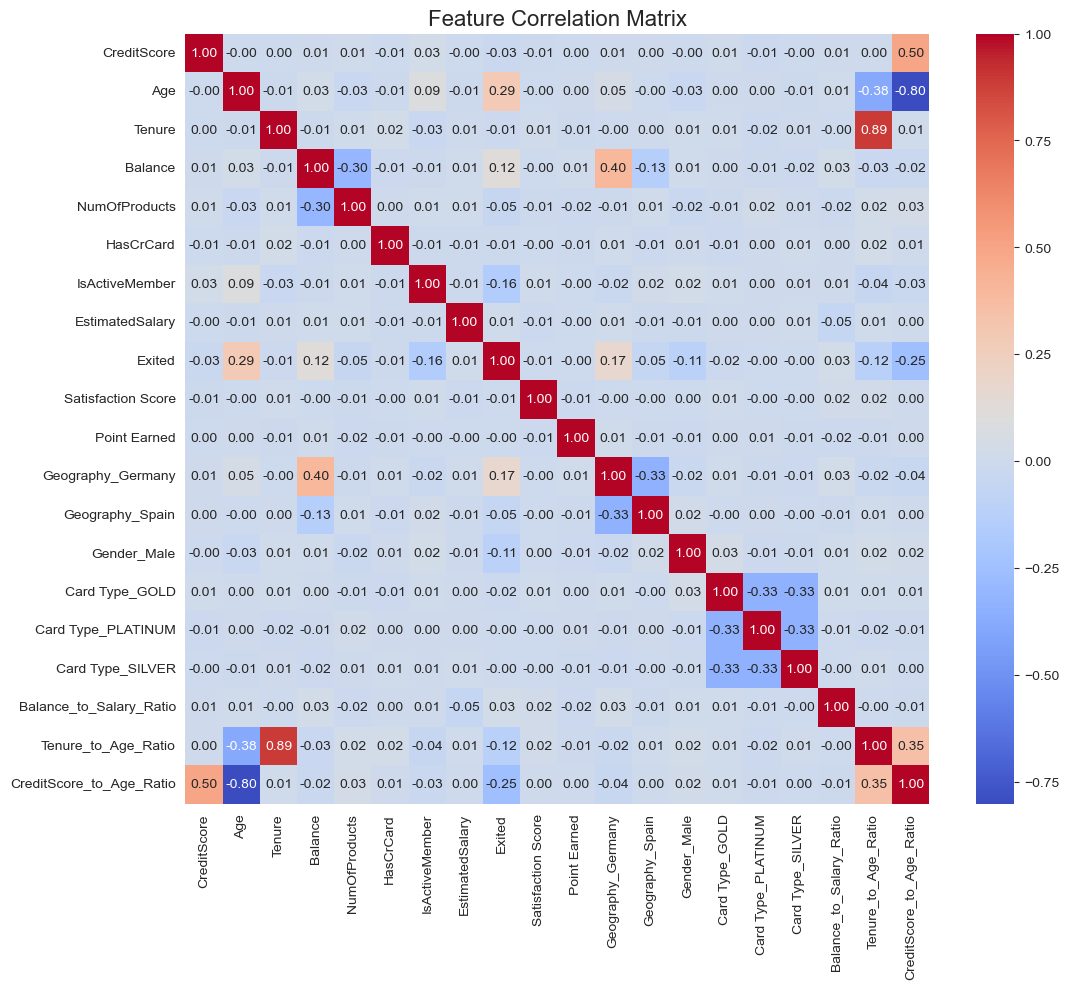

In [19]:
# Calculate the correlation matrix
correlation_matrix = df.corr(method='pearson', numeric_only=True)

# Plot the correlation matrix
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Feature Correlation Matrix', fontsize=16)
plt.show()

In [20]:
# Select features with high correlation with the target variable 'Exited'
correlation_with_target = correlation_matrix['Exited'].sort_values(ascending=False)
correlation_with_target

Exited                      1.000000
Age                         0.285296
Geography_Germany           0.173313
Balance                     0.118577
Balance_to_Salary_Ratio     0.025546
EstimatedSalary             0.012490
Card Type_PLATINUM         -0.000276
Card Type_SILVER           -0.003834
Point Earned               -0.004628
Satisfaction Score         -0.005849
HasCrCard                  -0.006976
Tenure                     -0.013656
Card Type_GOLD             -0.015995
CreditScore                -0.026771
NumOfProducts              -0.047611
Geography_Spain            -0.052800
Gender_Male                -0.106267
Tenure_to_Age_Ratio        -0.121377
IsActiveMember             -0.156356
CreditScore_to_Age_Ratio   -0.253322
Name: Exited, dtype: float64

# Feature Selection

In [21]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
import pandas as pd

# Step 1: Split the data into training and testing sets
X = df.drop(columns=['Exited'])  # Predictor variables
y = df['Exited']  # Target variable

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
# Step 2: Calculate Mutual Information on the training set
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)

# Create a DataFrame for easy visualization
mi_scores_df = pd.DataFrame({'Feature': X_train.columns, 'Mutual_Information': mi_scores})
mi_scores_df = mi_scores_df.sort_values(by='Mutual_Information', ascending=False)

# Display the top features based on MI
print("Mutual Information Scores:")
print(mi_scores_df)

# Step 4: Select features with MI scores greater than 0
selected_features = mi_scores_df[mi_scores_df['Mutual_Information'] > 0]['Feature'].tolist()

print("\nSelected Features Based on Mutual Information (MI > 0):", selected_features)

# Step 5: Use the selected features for model training
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

Mutual Information Scores:
                     Feature  Mutual_Information
1                        Age            0.073869
4              NumOfProducts            0.070698
18  CreditScore_to_Age_Ratio            0.046904
17       Tenure_to_Age_Ratio            0.039822
6             IsActiveMember            0.014135
16   Balance_to_Salary_Ratio            0.012225
10         Geography_Germany            0.011100
3                    Balance            0.009897
8         Satisfaction Score            0.007044
0                CreditScore            0.005711
12               Gender_Male            0.005219
13            Card Type_GOLD            0.004882
2                     Tenure            0.004492
7            EstimatedSalary            0.003595
5                  HasCrCard            0.002548
9               Point Earned            0.001833
11           Geography_Spain            0.000000
14        Card Type_PLATINUM            0.000000
15          Card Type_SILVER            0.

In [23]:
# Display the shape of the selected feature sets
print("\nShape of X_train_selected:", X_train_selected.shape)
print("Shape of X_test_selected:", X_test_selected.shape)


Shape of X_train_selected: (8000, 16)
Shape of X_test_selected: (2000, 16)


In [24]:
X_train_selected.head()

,Age,NumOfProducts,CreditScore_to_Age_Ratio,Tenure_to_Age_Ratio,IsActiveMember,Balance_to_Salary_Ratio,Geography_Germany,Balance,Satisfaction Score,CreditScore,Gender_Male,Card Type_GOLD,Tenure,EstimatedSalary,HasCrCard,Point Earned
9254,32,2,21.437500,0.187500,1,0.000000,0.0,0.00,2,686,1.0,0.0,6,179093.26,1,510
1561,42,2,15.047619,0.095238,1,0.610395,1.0,119624.60,4,632,1.0,0.0,4,195978.86,1,959
1670,24,1,23.291667,0.125000,0,1.335878,0.0,114739.92,4,559,1.0,0.0,3,85891.02,1,327
6087,27,1,20.777778,0.333333,0,0.886051,0.0,135637.00,2,561,0.0,0.0,9,153080.40,1,567
6669,56,1,9.232143,0.160714,0,3.599756,0.0,142147.32,3,517,1.0,0.0,9,39488.04,0,727


# Scailing

In [25]:
print(type(X_train_selected))
print(X_train_selected.columns)
print(X_train_selected.index)

<class 'pandas.core.frame.DataFrame'>
Index(['Age', 'NumOfProducts', 'CreditScore_to_Age_Ratio',
       'Tenure_to_Age_Ratio', 'IsActiveMember', 'Balance_to_Salary_Ratio',
       'Geography_Germany', 'Balance', 'Satisfaction Score', 'CreditScore',
       'Gender_Male', 'Card Type_GOLD', 'Tenure', 'EstimatedSalary',
       'HasCrCard', 'Point Earned'],
      dtype='object')
Index([9254, 1561, 1670, 6087, 6669, 5933, 8829, 7945, 3508, 2002,
       ...
       8322, 5578, 4426,  466, 6265, 5734, 5191, 5390,  860, 7270],
      dtype='int64', length=8000)


In [26]:
# To use for models like NN, Logistic Regression 
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Scale data for models sensitive to scaling
X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

# Convert scaled data back to DataFrame for easier handling (optional)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train_selected.columns, index=X_train_selected.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test_selected.columns, index=X_test_selected.index)

# Keep unscaled data for tree-based models
X_train_unscaled = X_train_selected.copy()
X_test_unscaled = X_test_selected.copy()

# Verify scaling
print("Scaled Data (First 5 Rows):")
print(X_train_scaled.head())

print("\nUnscaled Data (First 5 Rows):")
print(X_train_unscaled.head())

Scaled Data (First 5 Rows):
           Age  NumOfProducts  CreditScore_to_Age_Ratio  Tenure_to_Age_Ratio  \
9254 -0.655786       0.808436                  0.649975             0.556060   
1561  0.294938       0.808436                 -0.532873            -0.476467   
1670 -1.416365      -0.916688                  0.993204            -0.143394   
6087 -1.131148      -0.916688                  0.527852             2.188118   
6669  1.625953      -0.916688                 -1.609391             0.256294   

      IsActiveMember  Balance_to_Salary_Ratio  Geography_Germany   Balance  \
9254        0.974817                -0.133123          -0.579467 -1.218471   
1561        0.974817                -0.103370           1.725723  0.696838   
1670       -1.025834                -0.068007          -0.579467  0.618629   
6087       -1.025834                -0.089933          -0.579467  0.953212   
6669       -1.025834                 0.042344          -0.579467  1.057449   

      Satisfaction Sco

In [27]:
print("Overlap before resampling:", set(X_train_scaled.index).intersection(set(X_test_scaled.index)))


Overlap before resampling: set()


# Balancing classes

In [28]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Initialize the resampling methods
oversampler = RandomOverSampler(random_state=42)
undersampler = RandomUnderSampler(random_state=42)
smote = SMOTE(random_state=42)

# Function to perform resampling
def resample_data(X, y, method):
    if method == 'oversample':
        X_resampled, y_resampled = oversampler.fit_resample(X, y)
    elif method == 'undersample':
        X_resampled, y_resampled = undersampler.fit_resample(X, y)
    elif method == 'smote':
        X_resampled, y_resampled = smote.fit_resample(X, y)
    else:
        raise ValueError("Invalid method. Choose 'oversample', 'undersample', or 'smote'.")
    return X_resampled, y_resampled

# Apply resampling methods to both scaled and unscaled datasets
def prepare_resampled_datasets():
    datasets = {}
    
    for method in ['oversample', 'undersample', 'smote']:
        # Resample scaled data
        X_s_resampled, y_s_resampled = resample_data(X_train_scaled, y_train, method)
        datasets[f's_{method}'] = (X_s_resampled, y_s_resampled)
        
        # Resample unscaled data
        X_u_resampled, y_u_resampled = resample_data(X_train_unscaled, y_train, method)
        datasets[f'u_{method}'] = (X_u_resampled, y_u_resampled)
    
    return datasets

# Generate resampled datasets
resampled_datasets = prepare_resampled_datasets()

# Access resampled datasets
X_s_over, y_s_over = resampled_datasets['s_oversample']
X_s_under, y_s_under = resampled_datasets['s_undersample']
X_s_smote, y_s_smote = resampled_datasets['s_smote']

X_u_over, y_u_over = resampled_datasets['u_oversample']
X_u_under, y_u_under = resampled_datasets['u_undersample']
X_u_smote, y_u_smote = resampled_datasets['u_smote']


In [30]:
# Perform some checks
print("Scaled Oversampled Dataset:", X_s_over.shape, y_s_over.shape)
print("Scaled Undersampled Dataset:", X_s_under.shape, y_s_under.shape)
print("Scaled SMOTE Dataset:", X_s_smote.shape, y_s_smote.shape)

print("Unscaled Oversampled Dataset:", X_u_over.shape, y_u_over.shape)
print("Unscaled Undersampled Dataset:", X_u_under.shape, y_u_under.shape)
print("Unscaled SMOTE Dataset:", X_u_smote.shape, y_u_smote.shape)


Scaled Oversampled Dataset: (12710, 16) (12710,)
Scaled Undersampled Dataset: (3290, 16) (3290,)
Scaled SMOTE Dataset: (12710, 16) (12710,)
Unscaled Oversampled Dataset: (12710, 16) (12710,)
Unscaled Undersampled Dataset: (3290, 16) (3290,)
Unscaled SMOTE Dataset: (12710, 16) (12710,)


In [31]:
from collections import Counter

print("Class Distribution in Scaled Oversampled Dataset:", Counter(y_s_over))
print("Class Distribution in Scaled Undersampled Dataset:", Counter(y_s_under))
print("Class Distribution in Scaled SMOTE Dataset:", Counter(y_s_smote))

print("Class Distribution in Unscaled Oversampled Dataset:", Counter(y_u_over))
print("Class Distribution in Unscaled Undersampled Dataset:", Counter(y_u_under))
print("Class Distribution in Unscaled SMOTE Dataset:", Counter(y_u_smote))


Class Distribution in Scaled Oversampled Dataset: Counter({0: 6355, 1: 6355})
Class Distribution in Scaled Undersampled Dataset: Counter({0: 1645, 1: 1645})
Class Distribution in Scaled SMOTE Dataset: Counter({0: 6355, 1: 6355})
Class Distribution in Unscaled Oversampled Dataset: Counter({0: 6355, 1: 6355})
Class Distribution in Unscaled Undersampled Dataset: Counter({0: 1645, 1: 1645})
Class Distribution in Unscaled SMOTE Dataset: Counter({0: 6355, 1: 6355})


In [32]:
print("Scaled Oversampled Dataset Columns:", X_s_over.columns)
print("Unscaled SMOTE Dataset Columns:", X_u_smote.columns)


Scaled Oversampled Dataset Columns: Index(['Age', 'NumOfProducts', 'CreditScore_to_Age_Ratio',
       'Tenure_to_Age_Ratio', 'IsActiveMember', 'Balance_to_Salary_Ratio',
       'Geography_Germany', 'Balance', 'Satisfaction Score', 'CreditScore',
       'Gender_Male', 'Card Type_GOLD', 'Tenure', 'EstimatedSalary',
       'HasCrCard', 'Point Earned'],
      dtype='object')
Unscaled SMOTE Dataset Columns: Index(['Age', 'NumOfProducts', 'CreditScore_to_Age_Ratio',
       'Tenure_to_Age_Ratio', 'IsActiveMember', 'Balance_to_Salary_Ratio',
       'Geography_Germany', 'Balance', 'Satisfaction Score', 'CreditScore',
       'Gender_Male', 'Card Type_GOLD', 'Tenure', 'EstimatedSalary',
       'HasCrCard', 'Point Earned'],
      dtype='object')


In [33]:
print("Number of Features in Scaled Oversampled Dataset:", X_s_over.shape[1])
print("Number of Features in Unscaled SMOTE Dataset:", X_u_smote.shape[1])


Number of Features in Scaled Oversampled Dataset: 16
Number of Features in Unscaled SMOTE Dataset: 16


In [34]:
print("Test Set Shape (Scaled):", X_test_scaled.shape, y_test.shape)
print("Test Set Shape (Unscaled):", X_test_unscaled.shape, y_test.shape)
print("Class Distribution in Test Set:", Counter(y_test))


Test Set Shape (Scaled): (2000, 16) (2000,)
Test Set Shape (Unscaled): (2000, 16) (2000,)
Class Distribution in Test Set: Counter({0: 1607, 1: 393})


# Model Building

In [35]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

### Decision Tree

Use unscaled data

We will build a baseline Decision Tree model first

In [33]:

# Function to train and evaluate a baseline Decision Tree
def baseline_decision_tree(X_train, y_train, X_test, y_test, dataset_name):
    print(f"\nBaseline Model Evaluation on {dataset_name} Dataset:")

    # Initialize the Decision Tree model
    dt_model = DecisionTreeClassifier(random_state=42)
    
    # Train the model
    dt_model.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = dt_model.predict(X_test)
    y_prob = dt_model.predict_proba(X_test)[:, 1]  # Probabilities for the positive class
    
    # Metrics
    conf_matrix = confusion_matrix(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    # Print metrics
    print("Confusion Matrix:")
    print(conf_matrix)
    
    print(f"\nAccuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1 Score: {f1:.2f}")
    print(f"ROC AUC Score: {roc_auc:.2f}")
    
    return dt_model



In [34]:
# Oversampled Dataset
dt_model_over = baseline_decision_tree(X_u_over, y_u_over, X_test_unscaled, y_test, "Oversampled")

# Undersampled Dataset
dt_model_under = baseline_decision_tree(X_u_under, y_u_under, X_test_unscaled, y_test, "Undersampled")

# SMOTE Dataset
dt_model_smote = baseline_decision_tree(X_u_smote, y_u_smote, X_test_unscaled, y_test, "SMOTE")




Baseline Model Evaluation on Oversampled Dataset:
Confusion Matrix:
[[1389  218]
 [ 209  184]]

Accuracy: 0.79
Precision: 0.46
Recall: 0.47
F1 Score: 0.46
ROC AUC Score: 0.67

Baseline Model Evaluation on Undersampled Dataset:
Confusion Matrix:
[[1113  494]
 [ 130  263]]

Accuracy: 0.69
Precision: 0.35
Recall: 0.67
F1 Score: 0.46
ROC AUC Score: 0.68

Baseline Model Evaluation on SMOTE Dataset:
Confusion Matrix:
[[1324  283]
 [ 174  219]]

Accuracy: 0.77
Precision: 0.44
Recall: 0.56
F1 Score: 0.49
ROC AUC Score: 0.69


In [35]:
# Check training accuracy for oversampled dataset
y_train_pred_over = dt_model_over.predict(X_u_over)
print("Training Accuracy (Oversampled):", accuracy_score(y_u_over, y_train_pred_over))

# Check training accuracy for undersampled dataset
y_train_pred_under = dt_model_under.predict(X_u_under)
print("Training Accuracy (Undersampled):", accuracy_score(y_u_under, y_train_pred_under))

# Check training accuracy for SMOTE dataset
y_train_pred_smote = dt_model_smote.predict(X_u_smote)
print("Training Accuracy (SMOTE):", accuracy_score(y_u_smote, y_train_pred_smote))


Training Accuracy (Oversampled): 1.0
Training Accuracy (Undersampled): 1.0
Training Accuracy (SMOTE): 1.0


The result shows that the model is overfitting, so we need to perform the Hyperparameter tuning

Hyperparameter Tuning

In [36]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid
param_grid = {
    'max_depth': [3, 4, 5, 6, 7, 9, 11],
    'min_samples_split': [2, 3, 4, 5, 6, 7],
    'min_samples_leaf': [2,4,6,8,10],
    'criterion': ['gini', 'entropy']
}

# Function to perform hyperparameter tuning and evaluation
def tune_decision_tree(X_train, y_train, X_test, y_test, dataset_name):
    print(f"\nHyperparameter Tuning on {dataset_name} Dataset:")

    # Initialize GridSearchCV
    grid_search = GridSearchCV(
        estimator=DecisionTreeClassifier(random_state=42),
        param_grid=param_grid,
        scoring='roc_auc',  # Use ROC AUC as the evaluation metric
        cv=5,
        verbose=1,
        n_jobs=-1  # Use all available processors
    )
    
    # Fit the grid search
    grid_search.fit(X_train, y_train)
    
    # Best parameters
    best_params = grid_search.best_params_
    print("\nBest Hyperparameters:", best_params)
    
    # Train the best model
    best_model = grid_search.best_estimator_
    best_model.fit(X_train, y_train)
    
    # Evaluate on the test set
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]
    
    # Metrics
    conf_matrix = confusion_matrix(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    # Print metrics
    print("Confusion Matrix:")
    print(conf_matrix)
    
    print(f"\nAccuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1 Score: {f1:.2f}")
    print(f"ROC AUC Score: {roc_auc:.2f}")
    
    return best_model, best_params


In [37]:
# Oversampled Dataset
best_model_over, best_params_over = tune_decision_tree(X_u_over, y_u_over, X_test_unscaled, y_test, "Oversampled")

# Undersampled Dataset
best_model_under, best_params_under = tune_decision_tree(X_u_under, y_u_under, X_test_unscaled, y_test, "Undersampled")

# SMOTE Dataset
best_model_smote, best_params_smote = tune_decision_tree(X_u_smote, y_u_smote, X_test_unscaled, y_test, "SMOTE")



Hyperparameter Tuning on Oversampled Dataset:
Fitting 5 folds for each of 420 candidates, totalling 2100 fits

Best Hyperparameters: {'criterion': 'entropy', 'max_depth': 11, 'min_samples_leaf': 2, 'min_samples_split': 2}
Confusion Matrix:
[[1317  290]
 [ 141  252]]

Accuracy: 0.78
Precision: 0.46
Recall: 0.64
F1 Score: 0.54
ROC AUC Score: 0.77

Hyperparameter Tuning on Undersampled Dataset:
Fitting 5 folds for each of 420 candidates, totalling 2100 fits

Best Hyperparameters: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 10, 'min_samples_split': 2}
Confusion Matrix:
[[1165  442]
 [  78  315]]

Accuracy: 0.74
Precision: 0.42
Recall: 0.80
F1 Score: 0.55
ROC AUC Score: 0.84

Hyperparameter Tuning on SMOTE Dataset:
Fitting 5 folds for each of 420 candidates, totalling 2100 fits

Best Hyperparameters: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 7}
Confusion Matrix:
[[1401  206]
 [ 142  251]]

Accuracy: 0.83
Precision: 0.55
Recall: 0.

Classification Report for Oversampled Dataset:
              precision    recall  f1-score   support

           0       0.90      0.82      0.86      1607
           1       0.46      0.64      0.54       393

    accuracy                           0.78      2000
   macro avg       0.68      0.73      0.70      2000
weighted avg       0.82      0.78      0.80      2000



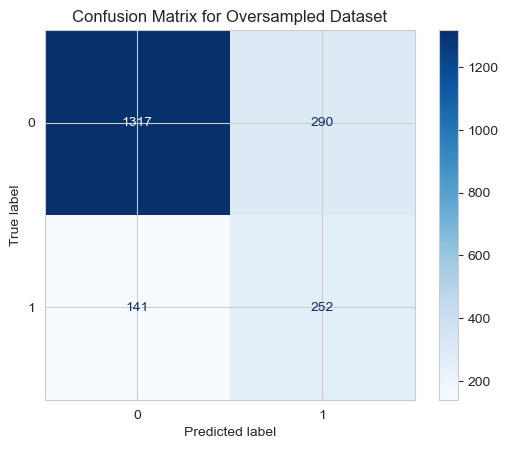

Classification Report for Undersampled Dataset:
              precision    recall  f1-score   support

           0       0.94      0.72      0.82      1607
           1       0.42      0.80      0.55       393

    accuracy                           0.74      2000
   macro avg       0.68      0.76      0.68      2000
weighted avg       0.83      0.74      0.76      2000



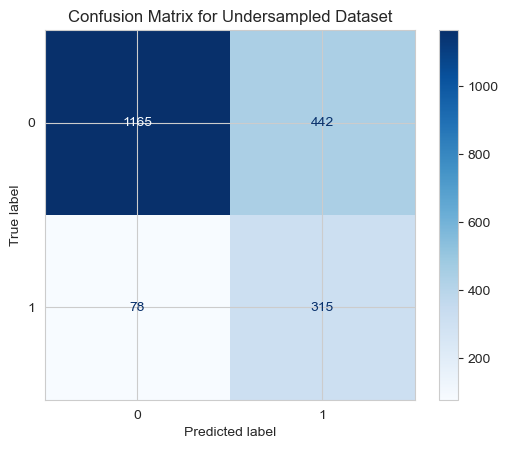

Classification Report for SMOTE Dataset:
              precision    recall  f1-score   support

           0       0.91      0.87      0.89      1607
           1       0.55      0.64      0.59       393

    accuracy                           0.83      2000
   macro avg       0.73      0.76      0.74      2000
weighted avg       0.84      0.83      0.83      2000



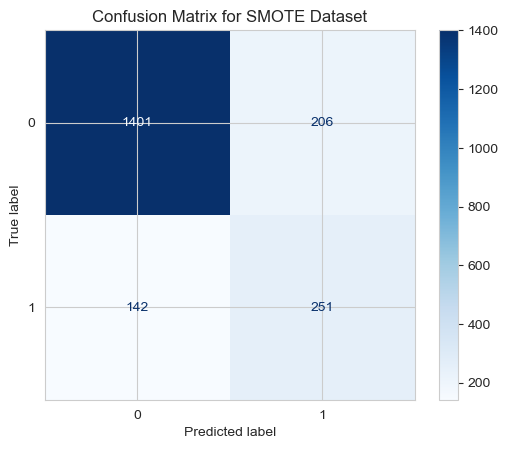

In [38]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Function to plot confusion matrix and classification report
def evaluate_model(best_model, X_test, y_test, dataset_name):
    # Predict on the test set
    y_pred = best_model.predict(X_test)
    
    # Classification Report
    print(f"Classification Report for {dataset_name} Dataset:")
    print(classification_report(y_test, y_pred))
    
    # Plot Confusion Matrix
    disp = ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, cmap="Blues", colorbar=True)
    disp.ax_.set_title(f"Confusion Matrix for {dataset_name} Dataset")
    plt.show()

# Evaluate the model on each dataset
evaluate_model(best_model_over, X_test_unscaled, y_test, "Oversampled")
evaluate_model(best_model_under, X_test_unscaled, y_test, "Undersampled")
evaluate_model(best_model_smote, X_test_unscaled, y_test, "SMOTE")


## Random Forest

Baseline


Baseline Random Forest Model on Oversampled Dataset:

Accuracy: 0.86
Precision: 0.69
Recall: 0.53
F1 Score: 0.60
ROC AUC Score: 0.85

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.94      0.92      1607
           1       0.69      0.53      0.60       393

    accuracy                           0.86      2000
   macro avg       0.79      0.74      0.76      2000
weighted avg       0.85      0.86      0.85      2000



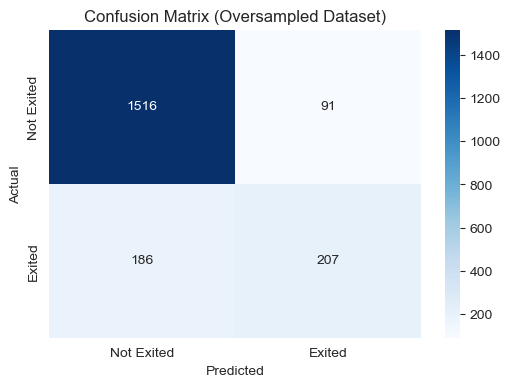


Baseline Random Forest Model on Undersampled Dataset:

Accuracy: 0.78
Precision: 0.47
Recall: 0.75
F1 Score: 0.57
ROC AUC Score: 0.86

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.79      0.85      1607
           1       0.47      0.75      0.57       393

    accuracy                           0.78      2000
   macro avg       0.70      0.77      0.71      2000
weighted avg       0.84      0.78      0.80      2000



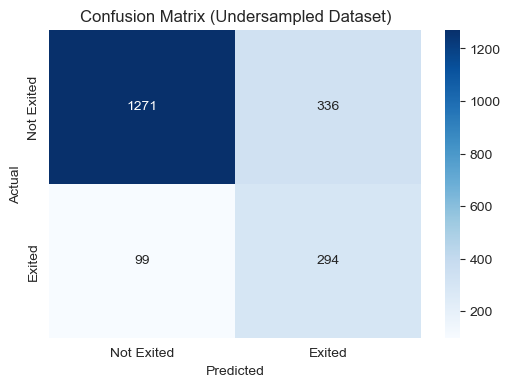


Baseline Random Forest Model on SMOTE Dataset:

Accuracy: 0.84
Precision: 0.62
Recall: 0.53
F1 Score: 0.57
ROC AUC Score: 0.85

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.92      0.90      1607
           1       0.62      0.53      0.57       393

    accuracy                           0.84      2000
   macro avg       0.75      0.73      0.74      2000
weighted avg       0.84      0.84      0.84      2000



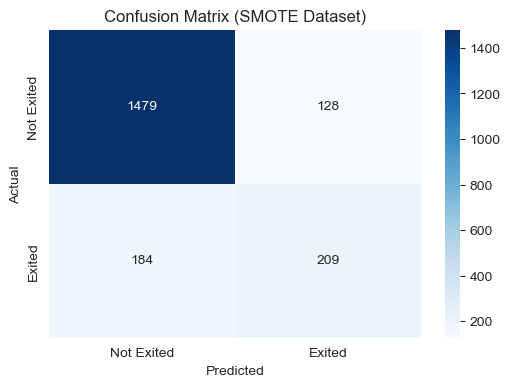

In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Function to train and evaluate a baseline Random Forest model
def baseline_random_forest(X_train, y_train, X_test, y_test, dataset_name):
    print(f"\nBaseline Random Forest Model on {dataset_name} Dataset:\n")
    
    # Initialize the Random Forest model with default hyperparameters
    rf_model = RandomForestClassifier(random_state=42)
    
    # Train the model
    rf_model.fit(X_train, y_train)
    
    # Make predictions on the test set
    y_pred = rf_model.predict(X_test)
    y_prob = rf_model.predict_proba(X_test)[:, 1]
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1 Score: {f1:.2f}")
    print(f"ROC AUC Score: {roc_auc:.2f}")
    
    # Classification Report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
    # Confusion Matrix
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Not Exited", "Exited"], yticklabels=["Not Exited", "Exited"])
    plt.title(f"Confusion Matrix ({dataset_name} Dataset)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# Run the baseline model for each dataset
baseline_random_forest(X_u_over, y_u_over, X_test_unscaled, y_test, "Oversampled")
baseline_random_forest(X_u_under, y_u_under, X_test_unscaled, y_test, "Undersampled")
baseline_random_forest(X_u_smote, y_u_smote, X_test_unscaled, y_test, "SMOTE")


Hyperparameter Tuning


Hyperparameter Tuning on Oversampled Dataset:

Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best Hyperparameters: {'criterion': 'entropy', 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 150}

Metrics on Test Data:
Accuracy: 0.86
Precision: 0.68
Recall: 0.55
F1 Score: 0.61
ROC AUC Score: 0.86

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.94      0.92      1607
           1       0.68      0.55      0.61       393

    accuracy                           0.86      2000
   macro avg       0.79      0.75      0.76      2000
weighted avg       0.85      0.86      0.86      2000



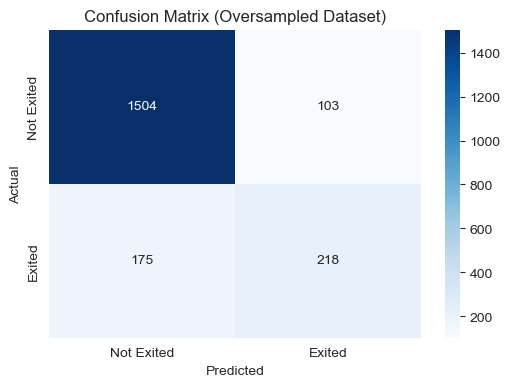


Hyperparameter Tuning on Undersampled Dataset:

Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best Hyperparameters: {'criterion': 'entropy', 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 150}

Metrics on Test Data:
Accuracy: 0.79
Precision: 0.48
Recall: 0.74
F1 Score: 0.59
ROC AUC Score: 0.86

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.81      0.86      1607
           1       0.48      0.74      0.59       393

    accuracy                           0.79      2000
   macro avg       0.71      0.77      0.72      2000
weighted avg       0.84      0.79      0.81      2000



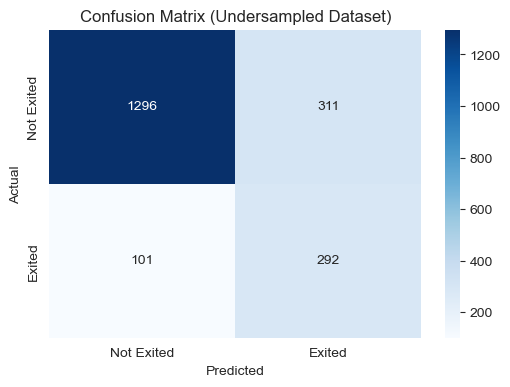


Hyperparameter Tuning on SMOTE Dataset:

Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best Hyperparameters: {'criterion': 'entropy', 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 150}

Metrics on Test Data:
Accuracy: 0.85
Precision: 0.63
Recall: 0.56
F1 Score: 0.60
ROC AUC Score: 0.85

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.92      0.91      1607
           1       0.63      0.56      0.60       393

    accuracy                           0.85      2000
   macro avg       0.77      0.74      0.75      2000
weighted avg       0.84      0.85      0.85      2000



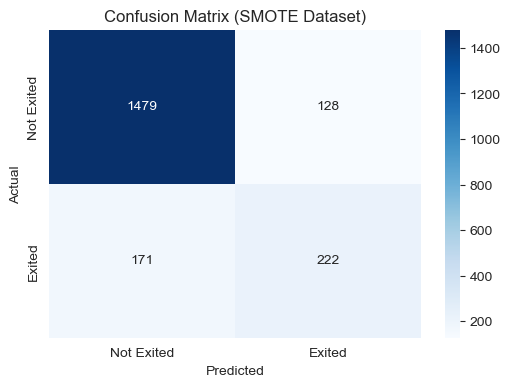

In [37]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [100, 150],              # Number of trees
    'max_depth': [10, 20],                 # Maximum depth of each tree
    'min_samples_split': [5, 10],            # Minimum number of samples to split a node
    'min_samples_leaf': [1, 2, 4],              # Minimum number of samples required at a leaf node
    'max_features': ['sqrt', 'log2'],           # Number of features to consider at each split
    'criterion': ['gini', 'entropy']            # Splitting criterion
}

# Function to perform hyperparameter tuning for Random Forest
def tune_random_forest(X_train, y_train, X_test, y_test, dataset_name):
    print(f"\nHyperparameter Tuning on {dataset_name} Dataset:\n")
    
    # Initialize Random Forest
    rf_model = RandomForestClassifier(random_state=42)
    
    # Set up GridSearchCV
    rf_grid_search = GridSearchCV(
        estimator=rf_model,
        param_grid=param_grid,
        scoring='roc_auc',  # Use ROC AUC as the evaluation metric
        cv=5,               # 5-fold cross-validation
        verbose=1,
        n_jobs=-1           # Use all available processors
    )
    
    # Fit the GridSearchCV
    rf_grid_search.fit(X_train, y_train)
    
    # Best parameters and model
    best_params = rf_grid_search.best_params_
    best_model = rf_grid_search.best_estimator_
    
    print(f"Best Hyperparameters: {best_params}")
    
    # Evaluate the best model on the test set
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]
    
    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    print(f"\nMetrics on Test Data:")
    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1 Score: {f1:.2f}")
    print(f"ROC AUC Score: {roc_auc:.2f}")
    
    # Classification Report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
    # Confusion Matrix
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Not Exited", "Exited"], yticklabels=["Not Exited", "Exited"])
    plt.title(f"Confusion Matrix ({dataset_name} Dataset)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    
    return best_model, best_params


# Run Hyperparameter Tuning for each dataset with updated variable names for Random Forest
best_model_rf_over, best_params_rf_over = tune_random_forest(X_u_over, y_u_over, X_test_unscaled, y_test, "Oversampled")
best_model_rf_under, best_params_rf_under = tune_random_forest(X_u_under, y_u_under, X_test_unscaled, y_test, "Undersampled")
best_model_rf_smote, best_params_rf_smote = tune_random_forest(X_u_smote, y_u_smote, X_test_unscaled, y_test, "SMOTE")



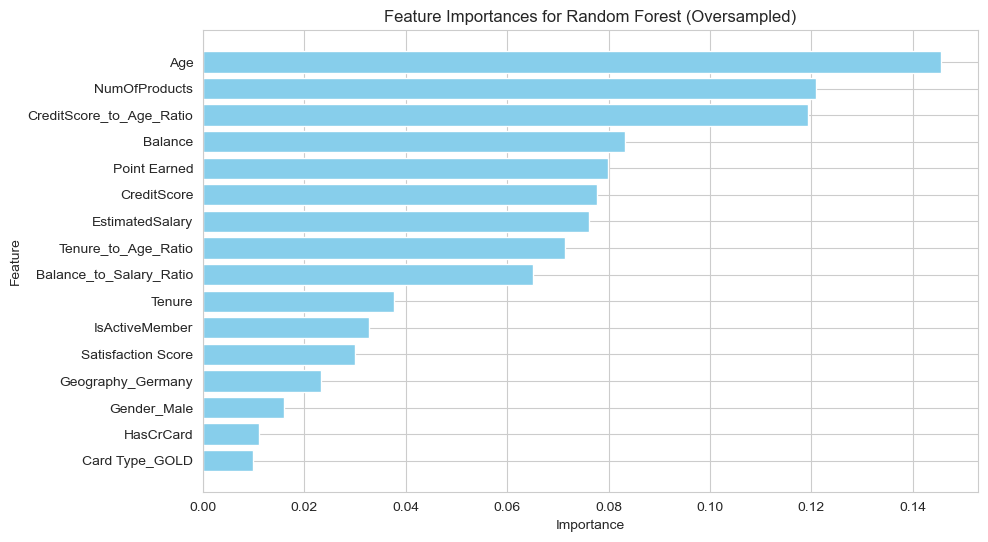

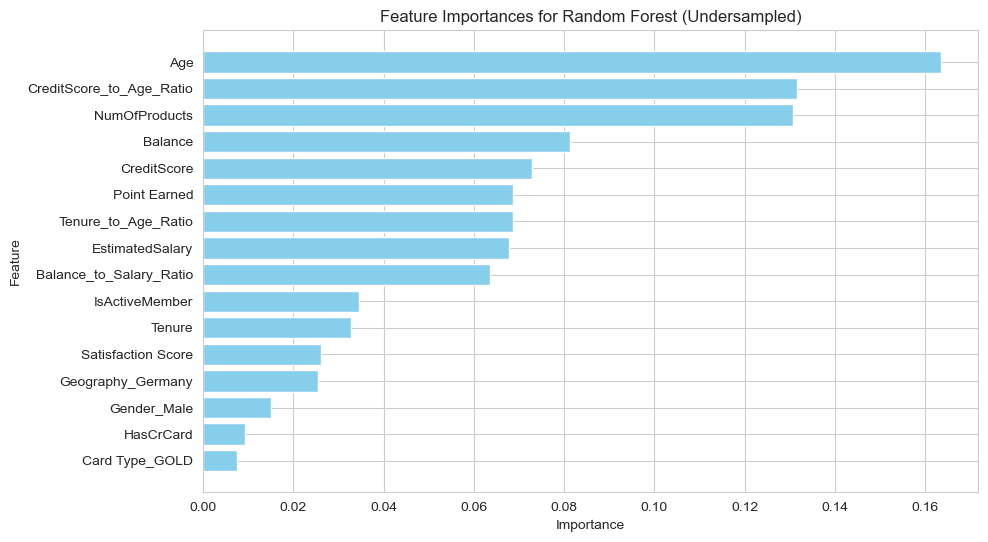

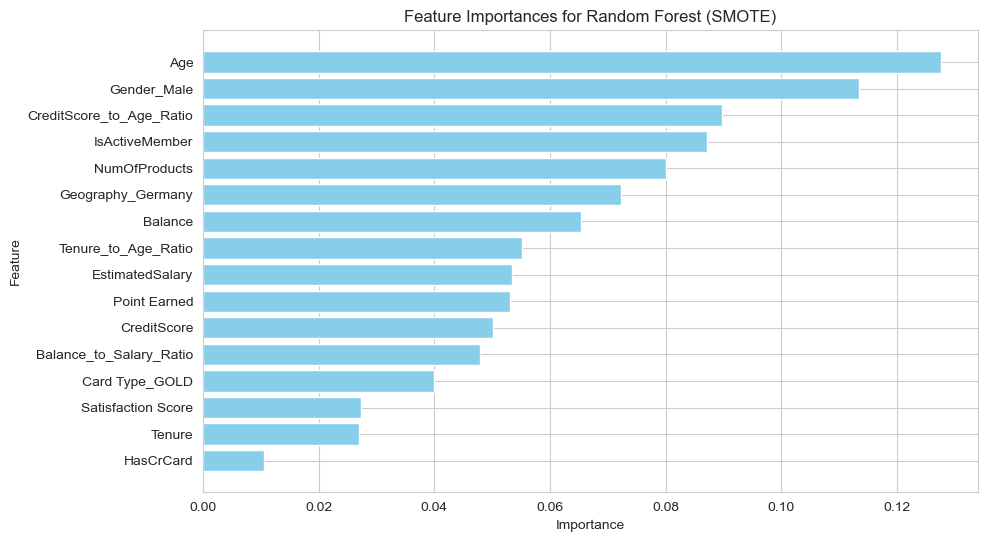

In [38]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def plot_feature_importance(model, feature_names, dataset_name):
    # Extract feature importances
    feature_importances = model.feature_importances_

    # Create a DataFrame for feature importance
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': feature_importances
    }).sort_values(by='Importance', ascending=False)

    # Plot the feature importance
    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'], color='skyblue')
    plt.gca().invert_yaxis()  # Invert y-axis to show the most important feature at the top
    plt.title(f'Feature Importances for Random Forest ({dataset_name})')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.show()

    return importance_df

# Assuming the feature names are in `X_train.columns`
feature_names = X_u_over.columns  # Change this based on the dataset used for training

# For Oversampled Dataset
importance_df_over = plot_feature_importance(best_model_rf_over, feature_names, "Oversampled")

# For Undersampled Dataset
importance_df_under = plot_feature_importance(best_model_rf_under, feature_names, "Undersampled")

# For SMOTE Dataset
importance_df_smote = plot_feature_importance(best_model_rf_smote, feature_names, "SMOTE")


## XGBoost

Baseline

Baseline XGBoost Model


E:\Anaconda\Lib\site-packages\xgboost\core.py:158: UserWarning: [09:40:40] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0c55ff5f71b100e98-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy: 0.86
Precision: 0.71
Recall: 0.49
F1 Score: 0.58
ROC AUC Score: 0.86

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.95      0.92      1607
           1       0.71      0.49      0.58       393

    accuracy                           0.86      2000
   macro avg       0.80      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000



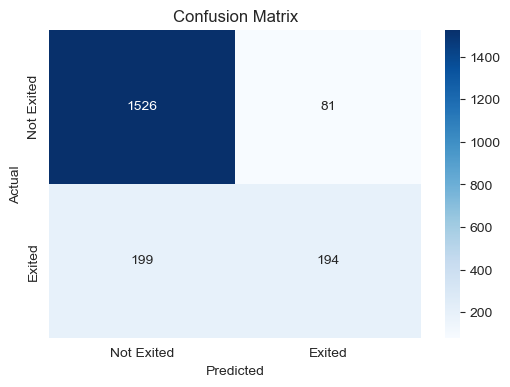

In [39]:
from xgboost import XGBClassifier

# Baseline XGBoost Model
def baseline_xgboost(X_train, y_train, X_test, y_test):
    print("Baseline XGBoost Model")
    
    # Initialize XGBoost with default hyperparameters
    xgb_model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
    
    # Train the model
    xgb_model.fit(X_train, y_train)
    
    # Make predictions
    y_pred = xgb_model.predict(X_test)
    y_prob = xgb_model.predict_proba(X_test)[:, 1]
    
    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1 Score: {f1:.2f}")
    print(f"ROC AUC Score: {roc_auc:.2f}")
    
    
    # Classification Report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
    # Confusion Matrix
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Not Exited", "Exited"], yticklabels=["Not Exited", "Exited"])
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# Call the function with unbalanced dataset
baseline_xgboost(X_train_unscaled, y_train, X_test_unscaled, y_test)

Tuning

Hyperparameter Tuning for XGBoost with GridSearchCV
Fitting 5 folds for each of 256 candidates, totalling 1280 fits


E:\Anaconda\Lib\site-packages\sklearn\model_selection\_validation.py:425: FitFailedWarning: 
7 fits failed out of a total of 1280.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
4 fits failed with the following error:
Traceback (most recent call last):
  File "E:\Anaconda\Lib\site-packages\sklearn\model_selection\_validation.py", line 732, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "E:\Anaconda\Lib\site-packages\xgboost\core.py", line 726, in inner_f
    return func(**kwargs)
           ^^^^^^^^^^^^^^
  File "E:\Anaconda\Lib\site-packages\xgboost\sklearn.py", line 1512, in fit
    train_dmatrix, evals = _wrap_evaluation_matrices(
                           ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "E:\Anaconda\Li

Best Hyperparameters: {'colsample_bytree': 0.8, 'gamma': 0.1, 'learning_rate': 0.05, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 100, 'scale_pos_weight': 1, 'subsample': 0.8}
Accuracy: 0.87
Precision: 0.77
Recall: 0.49
F1 Score: 0.60
ROC AUC Score: 0.87

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.77      0.49      0.60       393

    accuracy                           0.87      2000
   macro avg       0.83      0.72      0.76      2000
weighted avg       0.86      0.87      0.86      2000



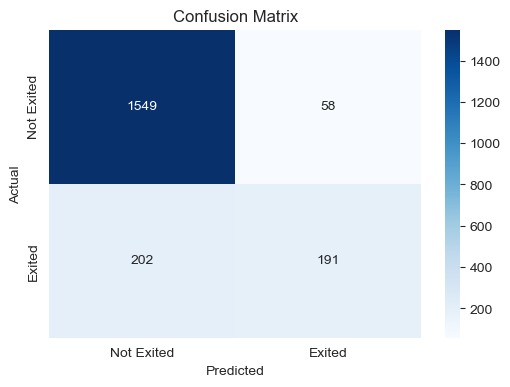

In [40]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [100, 200],                 # Number of trees
    'learning_rate': [0.05, 0.1],              # Learning rate (shrinkage)
    'max_depth': [3, 5],                       # Maximum depth of trees
    'min_child_weight': [1, 3],                # Minimum sum of instance weight needed in a child
    'gamma': [0, 0.1],                         # Minimum loss reduction for a split
    'subsample': [0.8, 1],                     # Fraction of samples for training
    'colsample_bytree': [0.8, 1],              # Fraction of features for each tree
    'scale_pos_weight': [1, 5]                 # Balancing for class imbalance
}

# Function to perform hyperparameter tuning for XGBoost
def tune_xgboost_with_gridsearch(X_train, y_train, X_test, y_test):
    print("Hyperparameter Tuning for XGBoost with GridSearchCV")
    
    # Initialize XGBoost
    xgb_model = XGBClassifier(random_state=42, use_label_encoder=False)
    
    # Set up GridSearchCV
    xgb_grid_search = GridSearchCV(
        estimator=xgb_model,
        param_grid=param_grid,
        scoring='roc_auc',
        cv=5,  # 5-fold cross-validation
        verbose=1,
        n_jobs=-1  # Use all available processors
    )
    
    # Fit GridSearchCV
    xgb_grid_search.fit(X_train, y_train)
    
    # Best parameters and model
    best_params = xgb_grid_search.best_params_
    best_model = xgb_grid_search.best_estimator_
    
    print(f"Best Hyperparameters: {best_params}")
    
    # Evaluate on the test set
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]
    
    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    # Print Metrics
    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1 Score: {f1:.2f}")
    print(f"ROC AUC Score: {roc_auc:.2f}")
    
    # Classification Report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
    # Confusion Matrix
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Not Exited", "Exited"], yticklabels=["Not Exited", "Exited"])
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    
    return best_model, best_params

# Call the function with unbalanced dataset
tuned_xgb_model, tuned_xgb_params = tune_xgboost_with_gridsearch(X_train_unscaled, y_train, X_test_unscaled, y_test)


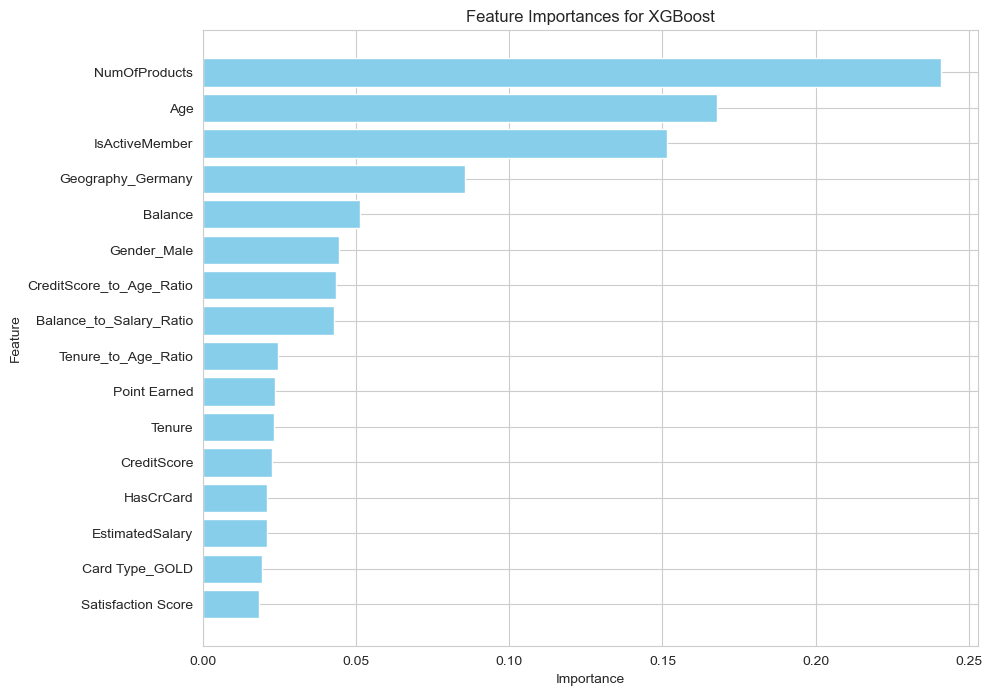

                     Feature  Importance
1              NumOfProducts    0.240965
0                        Age    0.167761
4             IsActiveMember    0.151438
6          Geography_Germany    0.085517
7                    Balance    0.051086
10               Gender_Male    0.044545
2   CreditScore_to_Age_Ratio    0.043300
5    Balance_to_Salary_Ratio    0.042761
3        Tenure_to_Age_Ratio    0.024336
15              Point Earned    0.023481
12                    Tenure    0.023300
9                CreditScore    0.022461
14                 HasCrCard    0.020835
13           EstimatedSalary    0.020834
11            Card Type_GOLD    0.019203
8         Satisfaction Score    0.018177


In [41]:
import matplotlib.pyplot as plt
import pandas as pd

# After the tuning process and evaluation
def plot_xgboost_feature_importance(model, feature_names):
    # Extract feature importances
    feature_importances = model.feature_importances_
    
    # Create a DataFrame for visualization
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': feature_importances
    }).sort_values(by='Importance', ascending=False)
    
    # Plot the feature importances
    plt.figure(figsize=(10, 8))
    plt.barh(importance_df['Feature'], importance_df['Importance'], color='skyblue')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.title('Feature Importances for XGBoost')
    plt.gca().invert_yaxis()  # Invert y-axis for better readability
    plt.show()

    return importance_df

# Call the function after the XGBoost tuning and evaluation
feature_names = X_train_unscaled.columns  # Replace with your feature column names
importance_df = plot_xgboost_feature_importance(tuned_xgb_model, feature_names)

# Print the importance dataframe for reference
print(importance_df)


## Logistic Regression

Baseline (without balancing)

Baseline Logistic Regression Performance:
Accuracy: 0.82
Precision: 0.59
Recall: 0.21
F1 Score: 0.31
ROC AUC Score: 0.78

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.96      0.89      1607
           1       0.59      0.21      0.31       393

    accuracy                           0.82      2000
   macro avg       0.71      0.59      0.60      2000
weighted avg       0.79      0.82      0.78      2000



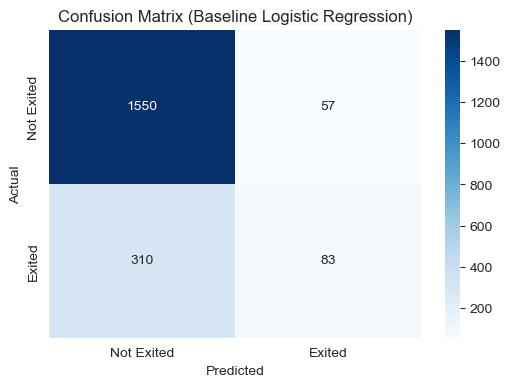

In [44]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression model
logreg_baseline = LogisticRegression(random_state=42)

# Train the model
logreg_baseline.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = logreg_baseline.predict(X_test_scaled)
y_prob = logreg_baseline.predict_proba(X_test_scaled)[:, 1]

# Evaluate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

# Print metrics
print("Baseline Logistic Regression Performance:")
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")
print(f"ROC AUC Score: {roc_auc:.2f}")

# Print classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Not Exited", "Exited"], yticklabels=["Not Exited", "Exited"])
plt.title("Confusion Matrix (Baseline Logistic Regression)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Since precision, recall and F1 score is not high -> tuning with the balanced dataset

Further tuning and with balancing dataset

In [45]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_grid = {
    'penalty': ['l1', 'l2', 'elasticnet'],    # Regularization type
    'C': [0.01, 0.1, 1, 10, 100],            # Inverse of regularization strength
    'solver': ['liblinear', 'saga'],          # Solvers compatible with penalties
    'l1_ratio': [0.1, 0.5, 0.9]              # Only used for elasticnet
}

def tune_logistic_regression(X_train, y_train, X_test, y_test, dataset_name):
    print(f"\nHyperparameter Tuning for Logistic Regression on {dataset_name} Dataset:\n")
    
    # Initialize Logistic Regression model
    logreg_model = LogisticRegression(random_state=42, max_iter=1000)
    
    # Set up GridSearchCV
    grid_search = GridSearchCV(
        estimator=logreg_model,
        param_grid=param_grid,
        scoring='roc_auc',  # Use ROC AUC as the evaluation metric
        cv=5,               # 5-fold cross-validation
        verbose=2,
        n_jobs=-1           # Use all available processors
    )
    
    # Fit GridSearchCV
    grid_search.fit(X_train, y_train)
    
    # Get the best parameters and model
    best_params = grid_search.best_params_
    best_model = grid_search.best_estimator_
    
    print(f"Best Hyperparameters: {best_params}")
    
    # Evaluate on the test set
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]
    
    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    print(f"\nMetrics on Test Data:")
    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1 Score: {f1:.2f}")
    print(f"ROC AUC Score: {roc_auc:.2f}")
    
    # Classification Report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
    # Confusion Matrix
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Not Exited", "Exited"], yticklabels=["Not Exited", "Exited"])
    plt.title(f"Confusion Matrix ({dataset_name} Dataset)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    
    return best_model, best_params



Hyperparameter Tuning for Logistic Regression on Unbalanced Dataset:

Fitting 5 folds for each of 90 candidates, totalling 450 fits


E:\Anaconda\Lib\site-packages\sklearn\model_selection\_validation.py:425: FitFailedWarning: 
75 fits failed out of a total of 450.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
75 fits failed with the following error:
Traceback (most recent call last):
  File "E:\Anaconda\Lib\site-packages\sklearn\model_selection\_validation.py", line 732, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "E:\Anaconda\Lib\site-packages\sklearn\base.py", line 1151, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "E:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py", line 1168, in fit
    solver = _check_solver(self.solver, self.penalty, self.dual)


Best Hyperparameters: {'C': 0.1, 'l1_ratio': 0.1, 'penalty': 'l1', 'solver': 'saga'}

Metrics on Test Data:
Accuracy: 0.82
Precision: 0.59
Recall: 0.20
F1 Score: 0.30
ROC AUC Score: 0.78

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.97      0.89      1607
           1       0.59      0.20      0.30       393

    accuracy                           0.82      2000
   macro avg       0.71      0.58      0.60      2000
weighted avg       0.78      0.82      0.78      2000



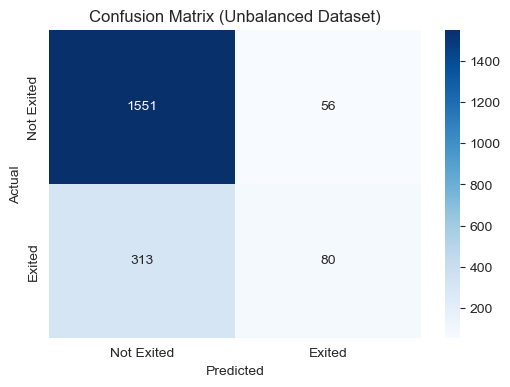


Hyperparameter Tuning for Logistic Regression on Oversampled Dataset:

Fitting 5 folds for each of 90 candidates, totalling 450 fits


E:\Anaconda\Lib\site-packages\sklearn\model_selection\_validation.py:425: FitFailedWarning: 
75 fits failed out of a total of 450.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
75 fits failed with the following error:
Traceback (most recent call last):
  File "E:\Anaconda\Lib\site-packages\sklearn\model_selection\_validation.py", line 732, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "E:\Anaconda\Lib\site-packages\sklearn\base.py", line 1151, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "E:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py", line 1168, in fit
    solver = _check_solver(self.solver, self.penalty, self.dual)


Best Hyperparameters: {'C': 0.01, 'l1_ratio': 0.1, 'penalty': 'l2', 'solver': 'saga'}

Metrics on Test Data:
Accuracy: 0.70
Precision: 0.37
Recall: 0.72
F1 Score: 0.49
ROC AUC Score: 0.78

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.70      0.79      1607
           1       0.37      0.72      0.49       393

    accuracy                           0.70      2000
   macro avg       0.64      0.71      0.64      2000
weighted avg       0.80      0.70      0.73      2000



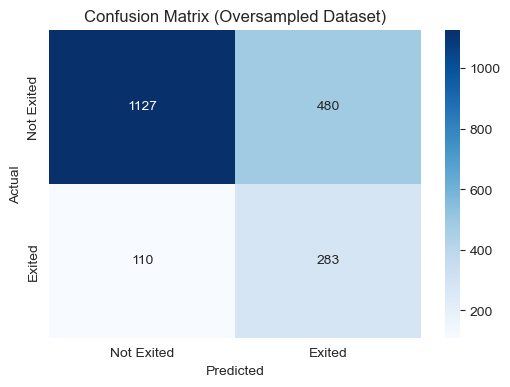


Hyperparameter Tuning for Logistic Regression on Undersampled Dataset:

Fitting 5 folds for each of 90 candidates, totalling 450 fits


E:\Anaconda\Lib\site-packages\sklearn\model_selection\_validation.py:425: FitFailedWarning: 
75 fits failed out of a total of 450.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
75 fits failed with the following error:
Traceback (most recent call last):
  File "E:\Anaconda\Lib\site-packages\sklearn\model_selection\_validation.py", line 732, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "E:\Anaconda\Lib\site-packages\sklearn\base.py", line 1151, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "E:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py", line 1168, in fit
    solver = _check_solver(self.solver, self.penalty, self.dual)


Best Hyperparameters: {'C': 0.01, 'l1_ratio': 0.1, 'penalty': 'elasticnet', 'solver': 'saga'}

Metrics on Test Data:
Accuracy: 0.71
Precision: 0.38
Recall: 0.73
F1 Score: 0.50
ROC AUC Score: 0.78

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1607
           1       0.38      0.73      0.50       393

    accuracy                           0.71      2000
   macro avg       0.65      0.72      0.65      2000
weighted avg       0.81      0.71      0.74      2000



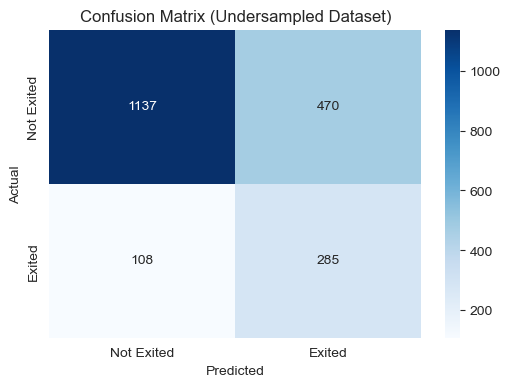


Hyperparameter Tuning for Logistic Regression on SMOTE Dataset:

Fitting 5 folds for each of 90 candidates, totalling 450 fits


E:\Anaconda\Lib\site-packages\sklearn\model_selection\_validation.py:425: FitFailedWarning: 
75 fits failed out of a total of 450.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
75 fits failed with the following error:
Traceback (most recent call last):
  File "E:\Anaconda\Lib\site-packages\sklearn\model_selection\_validation.py", line 732, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "E:\Anaconda\Lib\site-packages\sklearn\base.py", line 1151, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "E:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py", line 1168, in fit
    solver = _check_solver(self.solver, self.penalty, self.dual)


Best Hyperparameters: {'C': 0.1, 'l1_ratio': 0.1, 'penalty': 'l1', 'solver': 'saga'}

Metrics on Test Data:
Accuracy: 0.71
Precision: 0.37
Recall: 0.71
F1 Score: 0.49
ROC AUC Score: 0.78

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.71      0.79      1607
           1       0.37      0.71      0.49       393

    accuracy                           0.71      2000
   macro avg       0.64      0.71      0.64      2000
weighted avg       0.80      0.71      0.73      2000



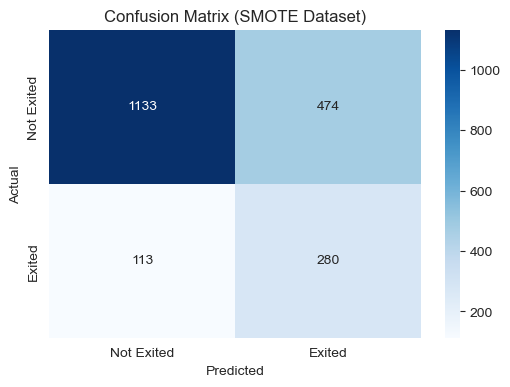

In [46]:
# Unbalanced Dataset
best_model_unbalanced, best_params_unbalanced = tune_logistic_regression(X_train_scaled, y_train, X_test_scaled, y_test, "Unbalanced")

# Oversampled Dataset
best_model_over, best_params_over = tune_logistic_regression(X_s_over, y_s_over, X_test_scaled, y_test, "Oversampled")

# Undersampled Dataset
best_model_under, best_params_under = tune_logistic_regression(X_s_under, y_s_under, X_test_scaled, y_test, "Undersampled")

# SMOTE Dataset
best_model_smote, best_params_smote = tune_logistic_regression(X_s_smote, y_s_smote, X_test_scaled, y_test, "SMOTE")


## Neural Network

Baseline

E:\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.85
Precision: 0.65
Recall: 0.52
F1 Score: 0.58
ROC AUC Score: 0.84

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.93      0.91      1607
           1       0.65      0.52      0.58       393

    accuracy                           0.85      2000
   macro avg       0.77      0.73      0.74      2000
weighted avg       0.84      0.85      0.84      2000



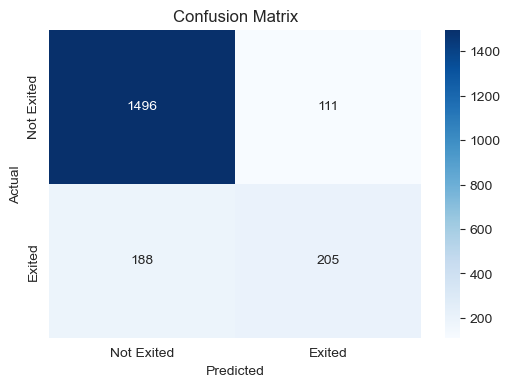

In [47]:
from sklearn.neural_network import MLPClassifier
# Initialize the model with default settings
mlp_baseline = MLPClassifier(random_state=42, max_iter=500)

# Fit the model to the scaled training dataset
mlp_baseline.fit(X_train_scaled, y_train)

# Predict on the test dataset
y_pred = mlp_baseline.predict(X_test_scaled)
y_prob = mlp_baseline.predict_proba(X_test_scaled)[:, 1]

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

# Print metrics
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")
print(f"ROC AUC Score: {roc_auc:.2f}")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Not Exited", "Exited"], yticklabels=["Not Exited", "Exited"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Tuning

Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best Parameters: {'activation': 'tanh', 'alpha': 0.01, 'hidden_layer_sizes': (100, 50), 'learning_rate': 'constant', 'solver': 'sgd'}
Accuracy: 0.86
Precision: 0.73
Recall: 0.49
F1 Score: 0.59
ROC AUC Score: 0.86

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.95      0.92      1607
           1       0.73      0.49      0.59       393

    accuracy                           0.86      2000
   macro avg       0.81      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000



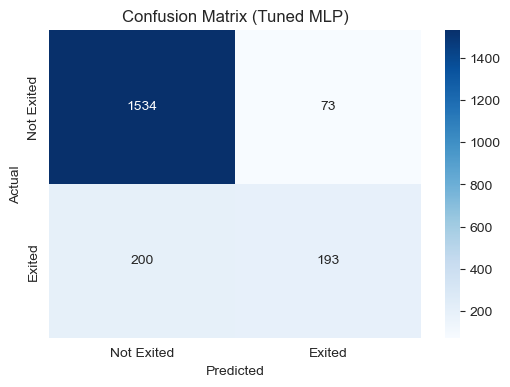

In [48]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50)],  # Number of neurons in hidden layers
    'activation': ['relu', 'tanh'],                             # Activation functions
    'solver': ['adam', 'sgd'],                                  # Optimizers
    'alpha': [0.0001, 0.001, 0.01],                             # L2 regularization
    'learning_rate': ['constant', 'adaptive'],                  # Learning rate schedule
}

# Set up GridSearchCV
mlp_grid_search = GridSearchCV(
    estimator=MLPClassifier(random_state=42, max_iter=500),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    verbose=1,
    n_jobs=-1
)

# Fit GridSearchCV
mlp_grid_search.fit(X_train_scaled, y_train)

# Get the best model and parameters
best_mlp_model = mlp_grid_search.best_estimator_
best_mlp_params = mlp_grid_search.best_params_

print(f"Best Parameters: {best_mlp_params}")

# Evaluate the best model
y_pred = best_mlp_model.predict(X_test_scaled)
y_prob = best_mlp_model.predict_proba(X_test_scaled)[:, 1]

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")
print(f"ROC AUC Score: {roc_auc:.2f}")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Not Exited", "Exited"], yticklabels=["Not Exited", "Exited"])
plt.title("Confusion Matrix (Tuned MLP)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


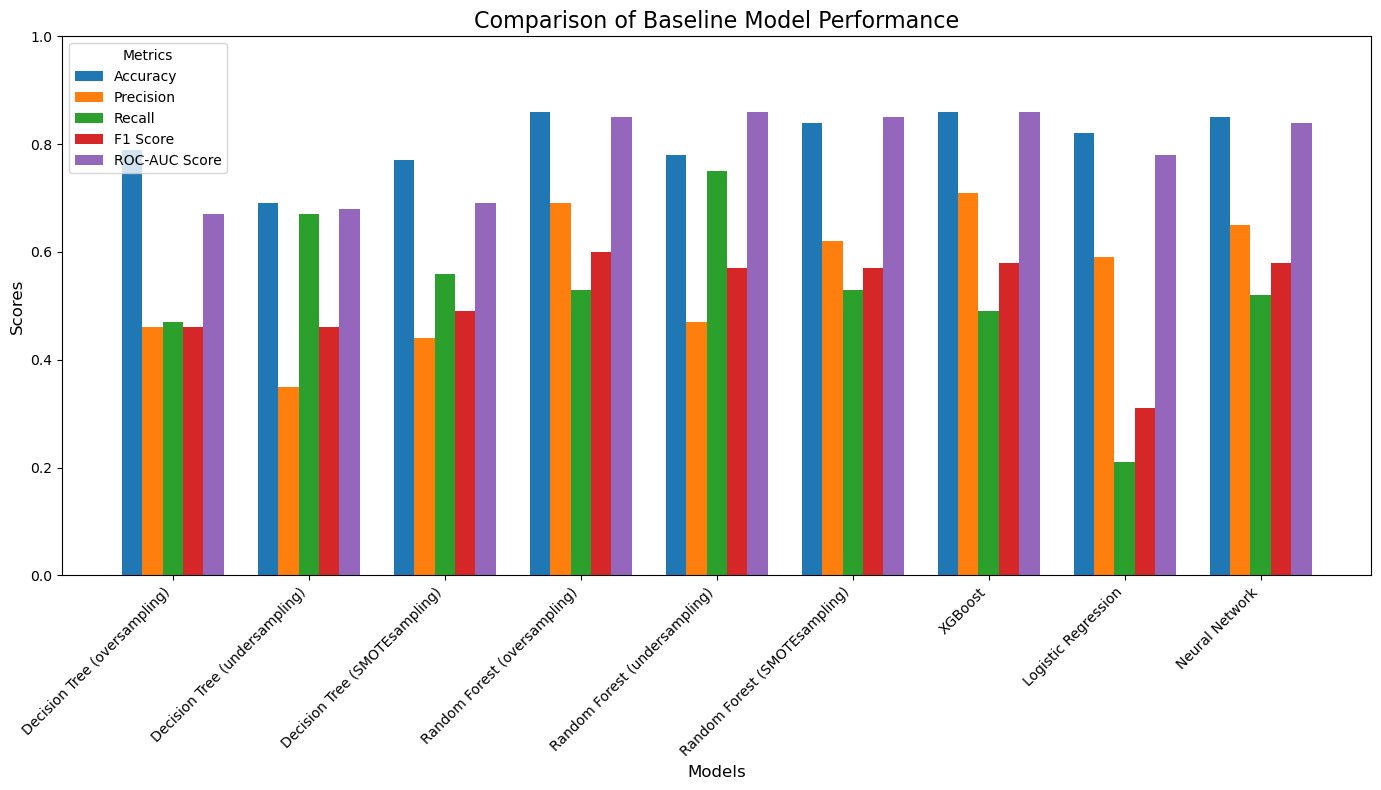

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Summarized metrics data
data = {
    "Model": [
        "Decision Tree (oversampling)", "Decision Tree (undersampling)", "Decision Tree (SMOTEsampling)",
        "Random Forest (oversampling)", "Random Forest (undersampling)", "Random Forest (SMOTEsampling)",
        "XGBoost", "Logistic Regression", "Neural Network"
    ],
    "Accuracy": [0.79, 0.69, 0.77, 0.86, 0.78, 0.84, 0.86, 0.82, 0.85],
    "Precision": [0.46, 0.35, 0.44, 0.69, 0.47, 0.62, 0.71, 0.59, 0.65],
    "Recall": [0.47, 0.67, 0.56, 0.53, 0.75, 0.53, 0.49, 0.21, 0.52],
    "F1 Score": [0.46, 0.46, 0.49, 0.60, 0.57, 0.57, 0.58, 0.31, 0.58],
    "ROC-AUC Score": [0.67, 0.68, 0.69, 0.85, 0.86, 0.85, 0.86, 0.78, 0.84]
}

# Convert data to a DataFrame for easier plotting
df = pd.DataFrame(data)

# Metrics to plot
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC Score"]

# Set up the figure
plt.figure(figsize=(14, 8))

# Create a bar plot for each metric
bar_width = 0.15
x = np.arange(len(df["Model"]))

for i, metric in enumerate(metrics):
    plt.bar(x + i * bar_width, df[metric], width=bar_width, label=metric)

# Add details to the chart
plt.xlabel("Models", fontsize=12)
plt.ylabel("Scores", fontsize=12)
plt.title("Comparison of Baseline Model Performance", fontsize=16)
plt.xticks(x + bar_width * (len(metrics) / 2 - 0.5), df["Model"], rotation=45, ha="right", fontsize=10)
plt.ylim(0, 1)
plt.legend(title="Metrics")
plt.tight_layout()

# Display the chart
plt.show()
